In [25]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
from sklearn.model_selection import train_test_split

sns.set_theme()

df_yelp = pd.read_csv("yelp.csv")
df_yelp.head()


,Unnamed: 0,business_id,date,review_id,stars,text,type,user_id,cool,useful,funny
0,0,9yKzy9PApeiPPOUJEtnvkg,2011-01-26,fWKvX83p0-ka4JS3dc6E5A,5,My wife took me here on my birthday for breakf...,review,rLtl8ZkDX5vH5nAx9C3q5Q,2,5,0
1,1,ZRJwVLyzEJq1VAihDhYiow,2011-07-27,IjZ33sJrzXqU-0X6U8NwyA,5,I have no idea why some people give bad review...,review,0a2KyEL0d3Yb1V6aivbIuQ,0,0,0
2,2,6oRAC4uyJCsJl1X0WZpVSA,2012-06-14,IESLBzqUCLdSzSqm0eCSxQ,4,love the gyro plate. Rice is so good and I als...,review,0hT2KtfLiobPvh6cDC8JQg,0,1,0
3,3,_1QQZuf4zZOyFCvXc0o6Vg,2010-05-27,G-WvGaISbqqaMHlNnByodA,5,"Rosie, Dakota, and I LOVE Chaparral Dog Park!!...",review,uZetl9T0NcROGOyFfughhg,1,2,0
4,4,6ozycU1RpktNG2-1BroVtw,2012-01-05,1uJFq2r5QfJG_6ExMRCaGw,5,General Manager Scott Petello is a good egg!!!...,review,vYmM4KTsC8ZfQBg-j5MWkw,0,0,0


In [26]:
df_yelp = df_yelp[["text","stars"]]
df_yelp.isnull().sum()

text     0
stars    0
dtype: int64

In [27]:
print(f"The total number of duplicates in the Yelp data set is: {df_yelp.duplicated().sum()}")

The total number of duplicates in the Yelp data set is: 2


In [28]:
df_yelp.drop_duplicates(inplace=True)
df_yelp.reset_index(drop=True,inplace=True)

In [29]:
print(f"The total number of duplicates in the Yelp data set is: {df_yelp.duplicated().sum()}")

The total number of duplicates in the Yelp data set is: 0


stars
4    3526
5    3336
3    1461
2     926
1     749
Name: count, dtype: int64


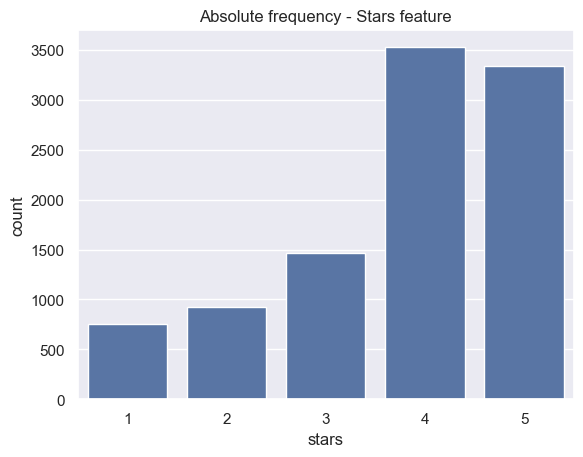

In [11]:
print(df_yelp["stars"].value_counts())
sns.countplot(data=df_yelp, x="stars")
plt.title("Absolute frequency - Stars feature")
plt.show()

In [30]:
df_yelp["sentiment"] = ""

for i in range(len(df_yelp)):
    if df_yelp.loc[i,"stars"] >= 3:
        df_yelp.loc[i,"sentiment"] = "Positive"
    else:
        df_yelp.loc[i,"sentiment"] = "Negative"


df_yelp['sentiment'] = df_yelp['sentiment'].map({'Negative': 0, 'Positive': 2})
df_yelp.head()

,text,stars,sentiment
0,My wife took me here on my birthday for breakf...,5,2
1,I have no idea why some people give bad review...,5,2
2,love the gyro plate. Rice is so good and I als...,4,2
3,"Rosie, Dakota, and I LOVE Chaparral Dog Park!!...",5,2
4,General Manager Scott Petello is a good egg!!!...,5,2


In [31]:
import re                                                                   # Regular expressions for text cleaning
import nltk                                                                 # Natural Language Toolkit library
from nltk.corpus import stopwords                                           # Import stopwords list
from nltk.stem import WordNetLemmatizer                                     # Import lemmatizer


STOPWORDS = set(stopwords.words("english"))                                 # Store English stopwords in a set (faster lookup)
lemmatizer = WordNetLemmatizer()                                            # Create lemmatizer object

def preprocess_text(text: str) -> str:                                      # Function takes text and returns cleaned text
    text = text.lower()                                                     # Convert text to lowercase
    text = re.sub(r"http\S+|www\S+", " ", text)                             # Remove URLs
    text = re.sub(r"@\w+", " ", text)                                       # Remove Twitter mentions (@username)
    text = re.sub(r"#", " ", text)                                          # Remove hashtag symbol only (keep the word)
    text = re.sub(r"[^a-z\s]", " ", text)                                   # Remove numbers and special characters (keep letters & spaces)
    text = re.sub(r"\s+", " ", text).strip()                                # Remove extra spaces    
    tokens = text.split()                                                   # Split text into individual words
    tokens = [lemmatizer.lemmatize(t)                                       # Lemmatize each word (convert to base form)
              for t in tokens                                               # Loop through each token
              if t not in STOPWORDS                                         # Remove stopwords
              and len(t) > 1]                                               # Remove very short words (length <= 1)

    return " ".join(tokens)    

df_yelp["text_cleaned"]= df_yelp["text"].apply(preprocess_text)

In [32]:
sample = df_yelp.sample(5, random_state = 42)[["text"]].copy()     # Randomly select 5 rows (fixed seed for reproducibility) and keep only 'text' and 'label' columns
sample["clean_text"] = sample["text"].apply(preprocess_text)       # Apply preprocessing function to the 'text' column and store results in a new column called 'clean_text'
sample

,text,clean_text
4122,I've been to Bookman's a few times and have mi...,bookman time mixed feeling going look around f...
4065,These are simply the BEST sandwiches and salad...,simply best sandwich salad like food locally g...
1731,"Every friday, my dad and I eat here. We order ...",every friday dad eat order thing pizza wrap go...
4740,Three stellar write-ups pushed me over the edg...,three stellar write ups pushed edge decided ti...
6391,Although a huge fan of bloody food. I have to ...,although huge fan bloody food say green really...


In [33]:
y_col = "stars"                                                                                                        

# Split into train and test sets into df
train_df, test_df = train_test_split(                            
    df_yelp,                                                     
    test_size = 0.25,                                            
    random_state = 42,                                           
    stratify = df_yelp[y_col]                                    
)

train_df = train_df.reset_index(drop = True)                              
test_df  = test_df.reset_index(drop = True)   

In [34]:
train_df

,text,stars,sentiment,text_cleaned
0,I go here for the free wifi and the bleu chees...,4,2,go free wifi bleu cheese crumble salad bleu ch...
1,"I'm going to be an uptight stickler here, and ...",5,2,going uptight stickler review pizzeria portion...
2,I have been coming to this place for atleast 5...,5,2,coming place atleast year favorite friend whol...
3,Been here twice now and tried two different do...,5,2,twice tried two different dog two side nothing...
4,I had such a great time at this place both tim...,5,2,great time place time went first visit sushi d...
...,...,...,...,...
7493,This is my favorite restaurant in Tempe. The f...,5,2,favorite restaurant tempe food great many vege...
7494,Cesar Chavez park is the best that the SW Vall...,4,2,cesar chavez park best sw valley offer located...
7495,"Okay, did I say bad??\nWORSE.\nNegative five s...",1,0,okay say bad worse negative five star san dieg...
7496,I love the Tempe Library. The Culture Pass is ...,5,2,love tempe library culture pas great program a...


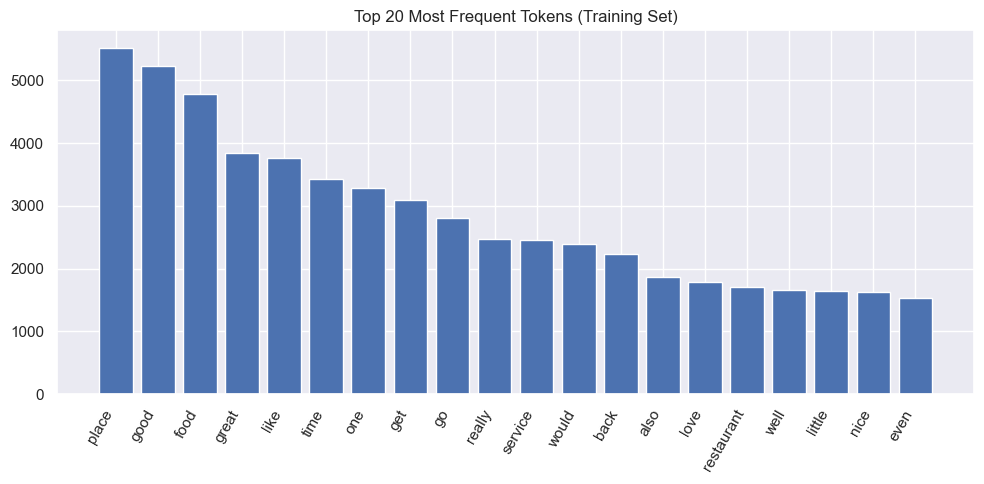

In [35]:
from collections import Counter                                         
import matplotlib.pyplot as plt                                         

all_tokens = " ".join(train_df["text_cleaned"]).split()                 

token_counts = Counter(all_tokens)                                      
top_n = 20                                                              

most_common = token_counts.most_common(top_n)                           
words, freqs = zip(*most_common)                                        
plt.figure(figsize = (10, 5))                                           
plt.bar(words, freqs)                                                   
plt.xticks(rotation = 60, ha = "right")                                 
plt.title(f"Top {top_n} Most Frequent Tokens (Training Set)")           
plt.tight_layout()                                                      
plt.show()       

In [37]:
from nltk.sentiment import SentimentIntensityAnalyzer                
sia = SentimentIntensityAnalyzer()                                   

def vader_label(text: str) -> int:                                   
    scores = sia.polarity_scores(text)                               
    c = scores["compound"]                                           
    if c >= 0.05:                                                    
        return 2                                                     
    elif c <= -0.05:                                                 
        return 0                                                     
    else:                                                            
        return 1                                                     

test_df["vader_pred"] = test_df["text_cleaned"].apply(vader_label)           

accuracy = (test_df["sentiment"] == test_df["vader_pred"]).mean()
print(f"\nAccuracy-text_cleaned:{round(accuracy,4)}")

test_df["vader_pred_2"] = test_df["text"].apply(vader_label)  
accuracy = (test_df["sentiment"] == test_df["vader_pred_2"]).mean()
print(f"\nAccuracy-text:{round(accuracy,4)}")


Accuracy-text_cleaned:0.8504

Accuracy-text:0.8636


**Findings:** I decided to apply vader to both columns: Text (the raw text from the data set) and text_cleaned (The text cleaned obtained by the preprocess_text function). and we can see that the accuracy from the raw text is slighly better than the one with cleaned text. 

* accuracy by using the raw text: 0.863
* accuracy by using the text cleaned: 0.850

In [38]:
test_df[["text","sentiment","vader_pred","vader_pred_2"]].head(5)

,text,sentiment,vader_pred,vader_pred_2
0,"The mall of malls, for sure! So many designer ...",2,2,2
1,Occasionally I just feel like going out for ju...,2,2,2
2,I have been trying to get into a consistent wo...,2,2,2
3,I actually yelped this restaurant from my brun...,0,2,2
4,The quintessential Brewery with a wholly fanta...,2,2,2


              precision    recall  f1-score   support

    Negative     0.7680    0.5609    0.6483       419
    Positive     0.9161    0.9659    0.9404      2081

    accuracy                         0.8980      2500
   macro avg     0.8421    0.7634    0.7943      2500
weighted avg     0.8913    0.8980    0.8914      2500



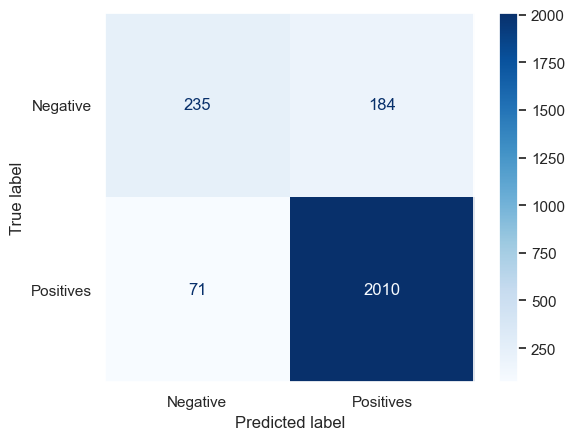

In [39]:
from sklearn.model_selection import train_test_split                     
from sklearn.feature_extraction.text import CountVectorizer              
from sklearn.linear_model import LogisticRegression                      
from sklearn.pipeline import Pipeline                                    
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay      

X_train = train_df["text_cleaned"]                                         
y_train = train_df["sentiment"]                                            

X_test = test_df["text_cleaned"]
y_test = test_df["sentiment"]                                              

model = Pipeline([                                                       
    ("bow", CountVectorizer(ngram_range = (1, 2), min_df = 2)),          
    ("clf", LogisticRegression(max_iter = 1000))                         
])

model.fit(X_train, y_train)                                              

pred = model.predict(X_test)                                             

bow_pred = pred                                                         

print(classification_report(y_test, pred, digits=4, target_names =["Negative","Positive"]))

cm = confusion_matrix(y_test, pred)

disp = ConfusionMatrixDisplay(
    confusion_matrix = cm,
    display_labels = ["Negative", "Positives"])

disp.plot(cmap = "Blues", values_format = "d")
plt.grid(False)
plt.show()

**Findings - classification_report:** From our results obtained above, we can state that our model accuracy is equal to 0.89.

##### Negative
* Our Precision for the **Negative** sentiment is equal to 0.76, which means that out 10 predictions our model predicted as **Negative** the **76%** of them were right.
* Our Recall for the **Negative** sentiment is equal to 0.56, which means that out of 10 real **Negative reviews**, we predicted correct only **56%** of them were right.

##### Positive
* Our Precision for the **Positive** sentiment is equal to 0.91, which means that out 10 predictions our model predicted as **Positive** the **91%** of them were right.
* Our Recall for the **Positive** sentiment is equal to 0.96, which means that out of 10 real **Positive reviews**, we predicted correct only **96%** of them were right.


**Findings - Confussion matrix:** From out plot above, we can state the next:

1) For the **negative sentiment**, our logistic regression model **predicted right 235 out of 419 reviews** (235 + 184)
2) For the **positive sentiment**, our logistic regression model **predicted right 2010 out of 2081 reviews** (2010 + 71)

In [40]:
from sklearn.metrics import accuracy_score                                     # Import accuracy metric

acc_results = {                                                                # Store all accuracies in one place
    "VADER": accuracy_score(test_df["sentiment"], test_df["vader_pred"]),          # Accuracy of VADER predictions
    "BoW + LR": accuracy_score(y_test, bow_pred),                              # Accuracy of CountVectorizer + Logistic Regression
}

for k, v in sorted(acc_results.items(), key=lambda x: x[1], reverse=True):     # Sort accuracies from best to worst
    print(f"{k:10s} accuracy: {v:.4f}")                                        # Print each accuracy neatly

BoW + LR   accuracy: 0.8980
VADER      accuracy: 0.8504


By looking at the results above, we can see that our accuracy in the **Bag of Words** model is better than the **Vader** model.
* **Vader** = **0.85**
* **BoW + LR** = **0.89**

## References


Geeksforgeeks.org. (2025). Welcome To Zscaler Directory Authentication. [online] Available at: https://www.geeksforgeeks.org/deep-learning/difference-between-keras-modelevaluate-and-modelpredict/.


GeeksforGeeks (2018). Activation functions in Neural Networks. [online] GeeksforGeeks. Available at: https://www.geeksforgeeks.org/machine-learning/activation-functions-neural-networks/. 


GeeksforGeeks (2019). Hyperparameter Tuning. [online] GeeksforGeeks. Available at: https://www.geeksforgeeks.org/machine-learning/hyperparameter-tuning/. 
Team, K. (n.d.). Keras documentation: Regression metrics. [online] keras.io. Available at: https://keras.io/api/metrics/regression_metrics/. 


Code from the week 9 / lecture 9 in which we executed Bag of words and LLM with our teacher Muhammad Iqbal. 